# 05: RQ4, session labels and what my preliminary score was measuring

RQ4 is the label-diagnostics question, and it has two halves. First: how much of the FatigueSet story depends on the subjective label filter? If I replace the primary labels with plain block-phase labels (early block alert, late block fatigued, no filter at all), does anything change under honest splits? Second: my preliminary experiment, one participant and two sessions, reported 99.18% recall for the fatigued class. This project rebuilt that setup exactly, and this notebook shows what the rebuilt version found.

## 0. Setup

In [1]:
# Setup. The pipeline in src/ is the engine; this notebook is a front door
# to it. Here I find the repository root, put the frozen modules and the
# pinned libraries on the path, and patch one NumPy rename.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if not hasattr(np, "trapz"):
    # NumPy 2.x renamed trapz to trapezoid. The frozen band-power module
    # still calls np.trapz, so I alias it here instead of editing frozen code.
    np.trapz = np.trapezoid


def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "features" / "bandpower.py").exists():
            return cand
    raise FileNotFoundError("repository root not found above the working directory")


ROOT = find_root()
for extra in (str(ROOT), str(Path.home() / "workspace" / ".pylibs")):
    if Path(extra).exists() and extra not in sys.path:
        sys.path.insert(0, extra)

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
PROC = ROOT / "data" / "processed"
pd.set_option("display.width", 120)
print("repository root:", ROOT)

repository root: /home/hatch/workspace/thesis-fatigue


## 1. Block-phase labels against the primary labels

The primary labels keep only the 32 sessions where the subjective rating rose, and label M1 windows alert and M3 windows fatigued. The block-phase arm drops the filter entirely: all 36 sessions, same blocks, same windows, same pipeline. If the FatigueSet null were an artefact of the filter, this arm would move.

In [2]:
rq4 = pd.read_csv(TAB / "rq4_aggregates.csv")
rq4[["arm", "protocol", "n_groups", "balanced_accuracy", "ba_ci95_low", "ba_ci95_high"]]

,arm,protocol,n_groups,balanced_accuracy,ba_ci95_low,ba_ci95_high
0,restricted32,within,8,0.483556,0.390226,0.564233
1,restricted32,session-out,20,0.515133,0.467918,0.554966
2,restricted32,loso,11,0.507804,0.471295,0.541935
3,all36,within,9,0.461309,0.371189,0.544981
4,all36,session-out,21,0.515439,0.469949,0.556277
5,all36,loso,11,0.516029,0.481947,0.547841


Under honest splits the filter changes almost nothing: leave-one-participant-out gives 0.516 with block-phase labels on all 36 sessions, against 0.508 with the primary labels on the restricted 32. The subjective-rise filter does not matter, and the labels were never the source of the FatigueSet null.

## 2. The preliminary setup, rebuilt exactly

The prototype used Subject 01 only, its own windowing (4-second windows with a 2-second stride across the whole stream, 1,353 windows), Session 01 as alert and Session 03 as fatigued, and a chronological 80/20 split. I rebuilt that configuration as closely as the stored data allows and ran both a logistic regression and the EEGNet CNN through it, plus a blocked split (60-second blocks assigned whole to train or test) as the intermediate step.

In [3]:
proto = pd.read_csv(TAB / "rq4_replication_proto_summary.csv")
proto[(proto.subset == "all")][["model", "split", "n", "n_alert", "n_fatigued",
                                 "balanced_accuracy", "recall_fatigued", "roc_auc"]]

,model,split,n,n_alert,n_fatigued,balanced_accuracy,recall_fatigued,roc_auc
0,lr,chronological,271,144,127,1.000000,1.000000,1.000000
3,cnn,chronological,271,144,127,0.993056,1.000000,1.000000
6,lr,blocked,240,120,120,0.975000,0.950000,0.999375
9,cnn,blocked,240,120,120,0.915278,0.841667,0.994352


The headline reproduces: logistic regression 1.000 and CNN 0.993 balanced accuracy on the chronological split, and the blocked split barely dents it (LR 0.975, CNN 0.915). So the score is real, in its own configuration. The next check asks what that configuration contains.

In [4]:
pidx = pd.read_csv(PROC / "windows_proto_p01_index.csv")
ret = pidx.groupby("session").a1_retained.agg(["mean", "count"])
ret.columns = ["share_retained_by_amendment1", "windows"]
ret

,share_retained_by_amendment1,windows
session,,
S01,0.970833,720
S03,0.025276,633


The mask is the finding. The Amendment 1 rules, applied to the prototype's own windows, keep 97.1% of the alert session and only 2.5% of the fatigued session. In the chronological test slice, every fatigued window is mask-rejected, so the retained test set contains no fatigued windows at all. The two sessions differ in a session-wide amplitude regime, strongest at AF7 but present across the headset, and the classifier's near-perfect score and the mask's rejection pattern are two views of the same difference.

## 3. Subject 01 under the fixed design

For completeness, the same participant under this project's design (Amendment 1 windows, subjective labels, the frozen baseline), rebuilt from the stored per-seed rows:

In [5]:
s01 = pd.read_csv(TAB / "subject01_fixed_design.csv")
s01[(s01.seed == "mean_of_s0-s4") & (s01.feature_set.str.contains("masked"))][
    ["protocol", "n", "balanced_accuracy", "roc_auc", "mcc"]]

,protocol,n,balanced_accuracy,roc_auc,mcc
5,within-subject (rotate held-out session),40.0,0.435714,0.404396,-0.155966
11,leave-one-session-out (held out P01/S01),22.0,0.382353,0.477647,-0.210470
17,leave-one-session-out (held out P01/S02),18.0,0.588889,0.543210,0.309146
23,LOPO (P01 held out),40.0,0.496154,0.480769,-0.009881
35,LOPO (P01 held out),40.0,0.508242,0.542857,0.019785
41,LOPO (P01 held out),40.0,0.496154,0.480220,-0.009881


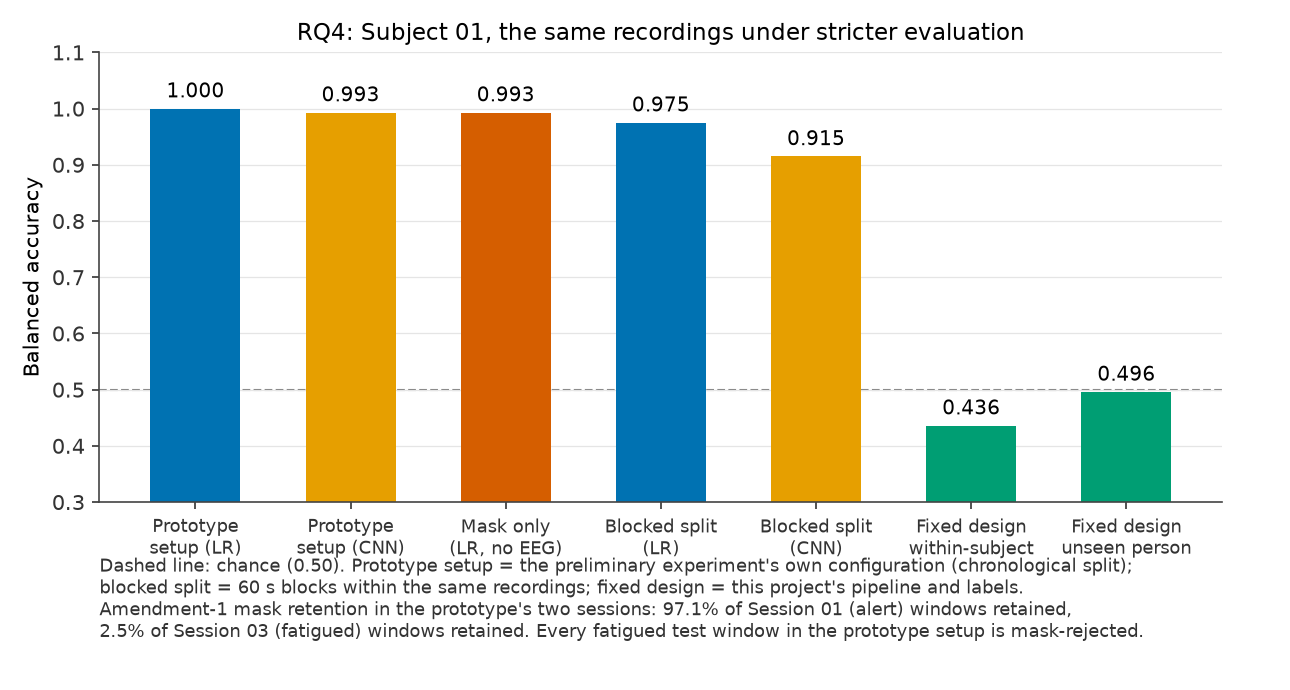

In [6]:
from IPython.display import Image

Image(filename=str(FIG / "fig_rq4_ladder.png"))

## 4. The locked reading

**The preliminary result reproduces in its own configuration, but there the fatigued class coincides almost perfectly with a session-wide amplitude regime that fails the pre-declared quality criterion (mask-retained 97.1% vs 2.5%). The score therefore identifies the session and cannot be read as evidence of fatigue decoding. The available data do not separate placement or contact differences from state-correlated physiology or behaviour.**

Three cautions stay attached. This is one participant, and the replication is post hoc. The word for the chronological arm is confound, not leakage: nothing leaked, the classes are simply not separable from the session in this design. And the mechanism question, placement and contact against physiology and behaviour, is not closed; it belongs in the limitations, with the data that would settle it (same-state repeat sessions with controlled placement).

Full write-up: `docs/rq4_session_labels.md`.